# Forecasting in Python

Below, an array of time series analysis techniques is given. To this purpose, the data of the number of COVID infections in Belgium is used. The data is available from Sciensano (https://epistat.sciensano.be/covid/). You first have to upload the correct 'COVID19BE_CASES_AGESEX.csv' file from BlackBoard to this environment.

First, the required Python packages are imported. We use the `statsmodels` package which covers all major time series forecasting algorithms and evaluation metrics:

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.exponential_smoothing import ExponentialSmoothing as SES
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.ar_model import AutoReg as AR
from statsmodels.tools.eval_measures import mse, meanabs
import pandas as pd
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

TS_PATH = "data/COVID19BE_CASES_AGESEX.csv" if os.path.exists("data/COVID19BE_CASES_AGESEX.csv") else "../data/COVID19BE_CASES_AGESEX.csv"

Next, we load the data:

In [8]:
df = pd.read_csv(TS_PATH)
df

,DATE,PROVINCE,REGION,AGEGROUP,SEX,CASES
0,2020-03-01,Antwerpen,Flanders,40-49,M,1
1,2020-03-01,Brussels,Brussels,10-19,F,1
2,2020-03-01,Brussels,Brussels,10-19,M,1
3,2020-03-01,Brussels,Brussels,20-29,M,1
4,2020-03-01,Brussels,Brussels,30-39,F,1
...,...,...,...,...,...,...
203104,2022-11-10,Antwerpen,Flanders,80-89,M,1
203105,2022-11-10,BrabantWallon,Wallonia,0-9,M,1
203106,2022-11-10,Brussels,Brussels,20-29,F,1
203107,2022-11-10,Limburg,Flanders,50-59,F,1


Since we have the data per province, region, etc. we first aggregate it to the daily level by grouping the data per unique date value and summing over all other levels:

In [9]:
df_cases = df.groupby(['DATE']).sum(numeric_only=True)
df_cases

,CASES
DATE,
2020-03-01,19
2020-03-02,19
2020-03-03,34
2020-03-04,53
2020-03-05,81
...,...
2022-11-06,273
2022-11-07,1319
2022-11-08,900


Working with `pandas` allows us to deal with dates, if we set the indexing correctly. We change the index explicitly to the date range of the dataset as follows (we could have extracted this automatically from the data, but let's do this hard-coded for simplicity's sake):

In [10]:
dates = pd.date_range(start="2020-03-01", end="2022-11-10")
df_cases.index = dates

One area in which this already helps is in obtaining time-based plots. Below we plot the number of cases over time:

<Axes: >

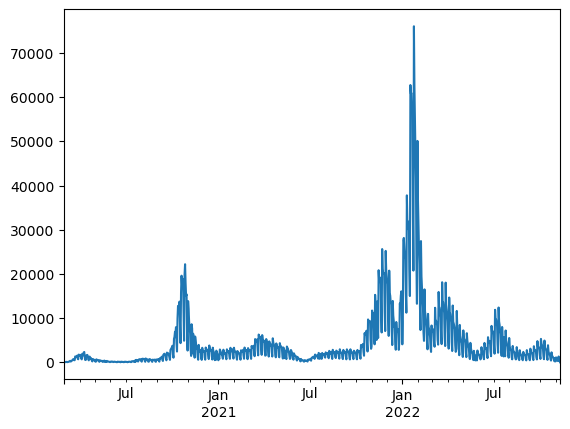

In [11]:
df_cases['CASES'].plot()

## Initial impression

We can get an initial idea of any autocorrelations by creating the autocorrelation and partial autocorrelation plots as follows:

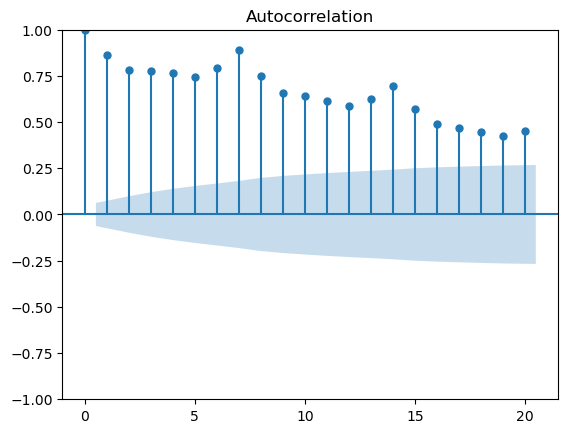

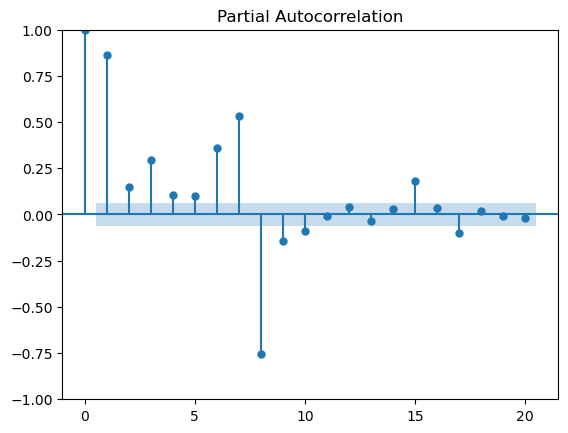

In [12]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(df_cases['CASES'], lags = 20)
plt.show()
plot_pacf(df_cases['CASES'], lags=20)
plt.show()

Clearly, there are very strong autocorrelations present.

We can apply differencing to see whether this improves things:

<Axes: >

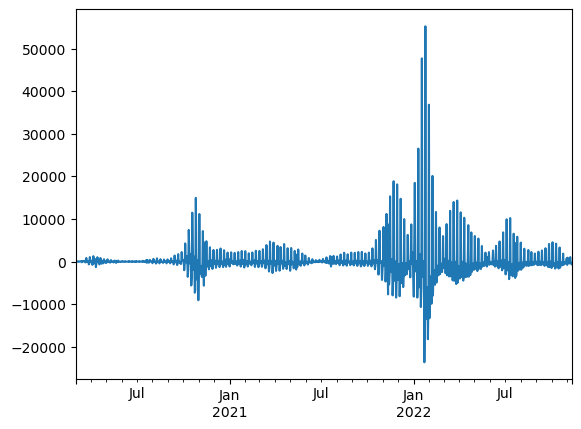

In [13]:
from statsmodels.tsa.statespace.tools import diff

diff(df_cases['CASES'], k_diff=1).plot()

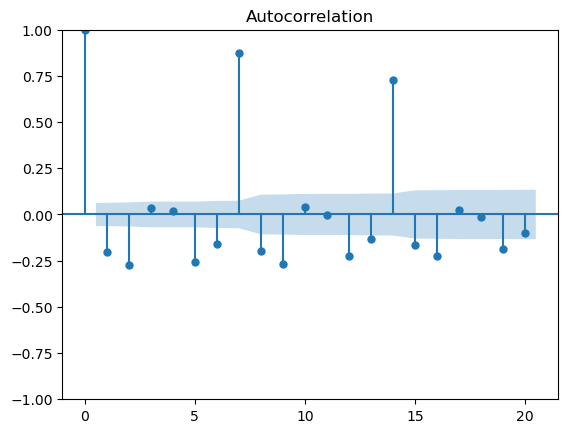

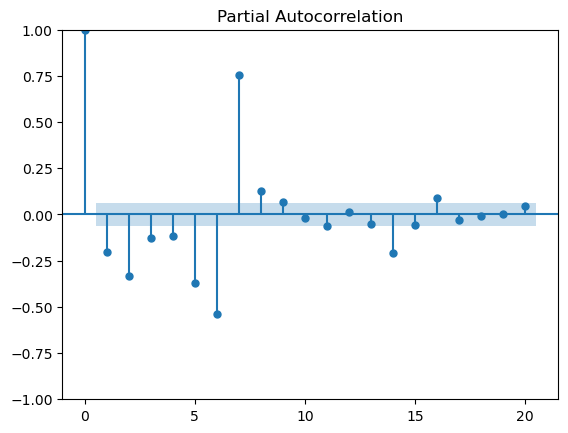

In [14]:
from statsmodels.tsa.statespace.tools import diff

plot_acf(diff(df_cases['CASES'], k_diff=1), lags = 20)
plt.show()
plot_pacf(diff(df_cases['CASES'], k_diff=1), lags=20)
plt.show()

We now use the Augmented Dickey-Fuller test to check whether the time series is stationary:

In [15]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(df_cases['CASES'])
print('Test statistic:', result[0])
print('P-value:', result[1])
print('Suggested number of lags:', result[2])

Test statistic: -3.8909485969402917
P-value: 0.0021024795365377183
Suggested number of lags: 16


Despite the ACF/PACF information, it appears the time series does not contain a unit root/trend as the test statistic is strongly negative and the null hypothesis of a unit root/trend being present is rejected. This means differencing is not necessary to make the series stationary.

## Decomposition

In order to get a first grasp of the data, we do a standard LOESS decomposition, obtaining separate trend, seasonality, and residual value information of our time series:

Text(0.5, 1.0, 'Residuals')

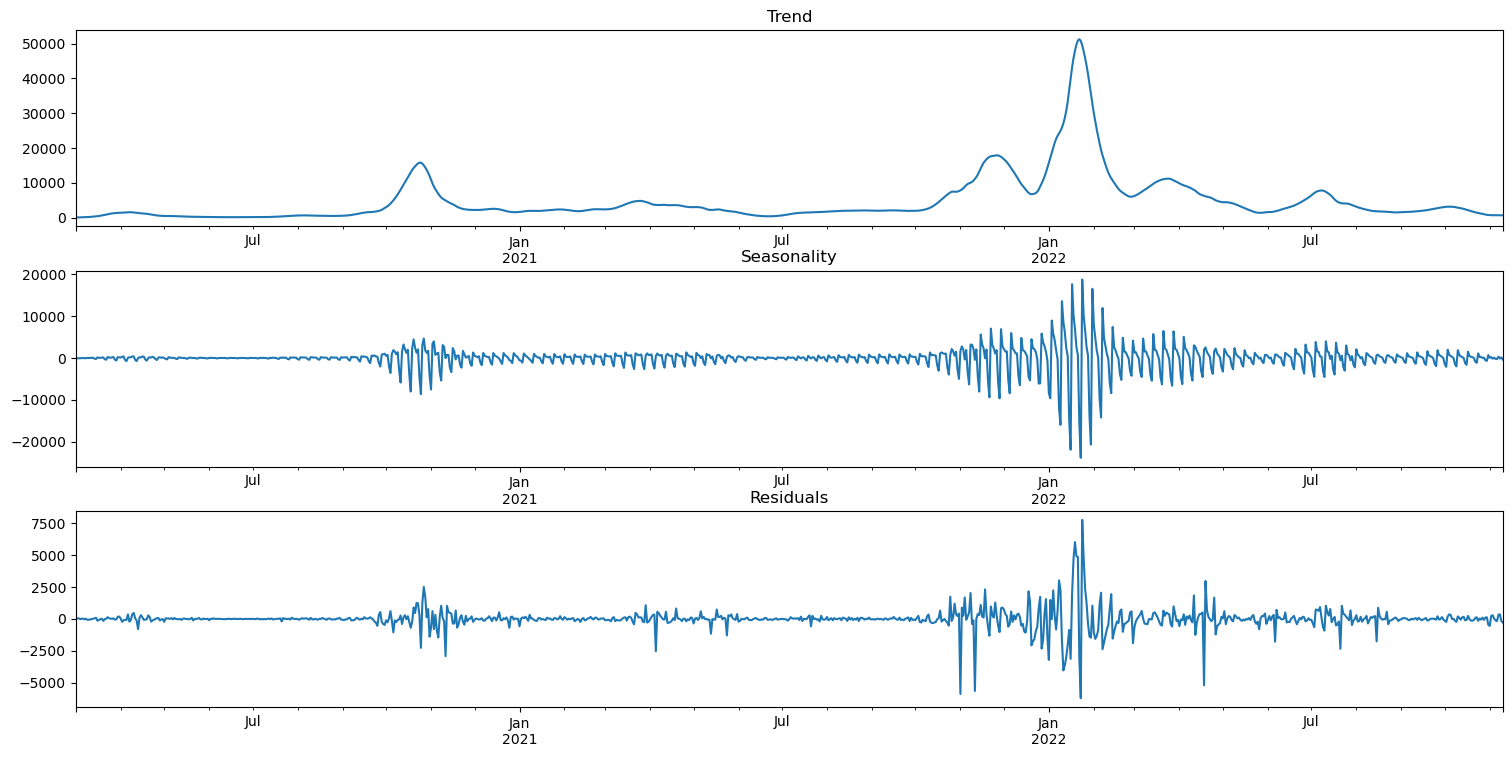

In [16]:
from statsmodels.tsa.seasonal import STL

# create a Season-Trend-Loess decomposition
decomposition = STL(df_cases['CASES'], seasonal=7).fit()


# visualization with 3 subplots (less important)
fig, (ax1,ax2,ax3) = plt.subplots(3,1, figsize=(15,8))
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
decomposition.trend.plot(ax=ax1)
ax1.set_title('Trend')
decomposition.seasonal.plot(ax=ax2)
ax2.set_title('Seasonality')
decomposition.resid.plot(ax=ax3)
ax3.set_title('Residuals')

Unfortunately, this is not the best time series to illustrate decomposition on. This is due to the fact that there are such strong peaks and a very odd seasonality. Although virologists have claimed that there are very strong seasonal effects, it is hard to pinpoint them on particular fixed time lags. This is further aggravated by the impact of vaccines and different virus variants.

## Forecasting

We will perform our first forecasting using an ARIMA model below.



In [17]:
import datetime as dt

# number of time steps we will forecast ahead
horizon = 500
# we single out our data for ease-of-use
x = df_cases['CASES']
# we only use data up to 2022
x = x.loc[:'2022']
test = x.loc['2022':]

# we build an ARIMA model of order p=2, d=1, q=2
# this might not be the best one and calculating AIC/BIC might be
# in order to determine the best parameters
model = ARIMA(x, order=(2, 1, 2))
# we fit the model
fit = model.fit()
# the fitted model can now be used to forecast, we forecast 200 time steps ahead
point_forecast = fit.get_prediction(start=test.index.min(), end=test.index.min() + dt.timedelta(days=horizon))
# this is the mean forecast
point_forecast.predicted_mean

2022-01-01    11978.688161
2022-01-02     6889.153740
2022-01-03    11617.575998
2022-01-04    20190.054202
2022-01-05    20199.272785
                  ...     
2023-05-12      501.550246
2023-05-13      501.550246
2023-05-14      501.550246
2023-05-15      501.550246
2023-05-16      501.550246
Freq: D, Name: predicted_mean, Length: 501, dtype: float64

Now we will visualize the forecast. Again, we forecast 500 time steps (days in this case) ahead. We reduce the time window of the training data as it has some very high numbers which distory the visualization.

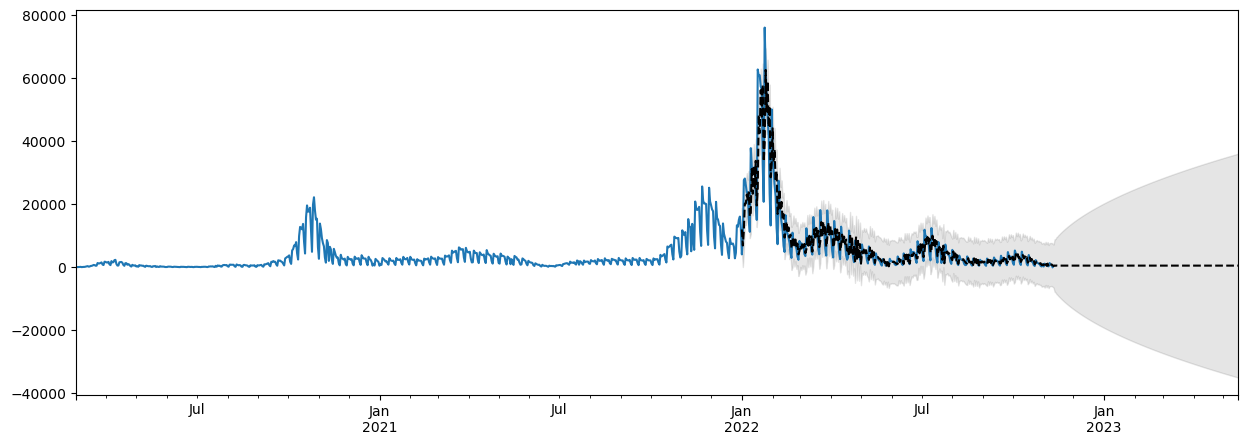

In [18]:
forecast = fit.get_prediction(start=test.index.min(), end=test.index.min() + dt.timedelta(days=horizon)).summary_frame()
fig, ax = plt.subplots(figsize=(15, 5))

# we only visualize the training set as of June 2022 as number before were
# much higher
x.plot(ax=ax)

# we plot the mean forecast
forecast['mean'].plot(ax=ax, style='k--')
# we add confidence intervals
ax.fill_between(forecast.index, forecast['mean_ci_lower'], forecast['mean_ci_upper'], color='k', alpha=0.1)

Naturally, the longer the forecast horizon, the wider the confidence intervals. It appears that the forecast is relatively flat towards the end.

## Benchmarking time series techniques

Similar to applying different classifiers in `scikit-learn`, it is also easy to use different forecasting algorithms with `statsmodels`. Below, we will benchmark exponential smoothing, AR, ARIMA, and a seasonal ARIMA over a training and an out-of-time test set:

In [19]:
x = df_cases['CASES']

# we use the data up to 2022 as training data
train = x.loc[:'2022']
# data as of 2022 are used as test data
test = x.loc['2022':]
# number of observations in each
print(len(train))
print(len(test))

985
314


Now we build 4 different models, including a seasonal ARIMA model, and visualize their forecast. Note that this setup seems to work much better than the previous example.

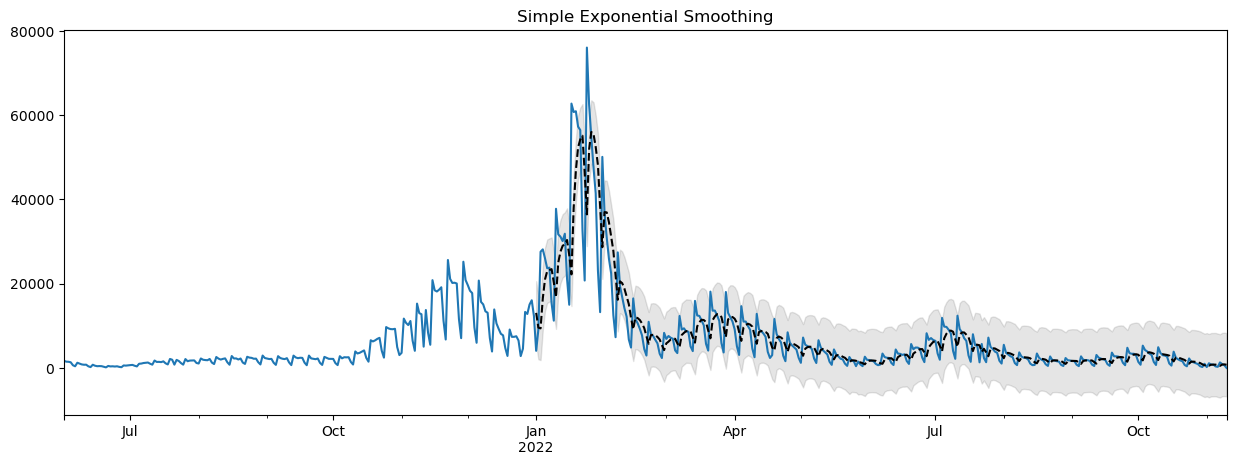

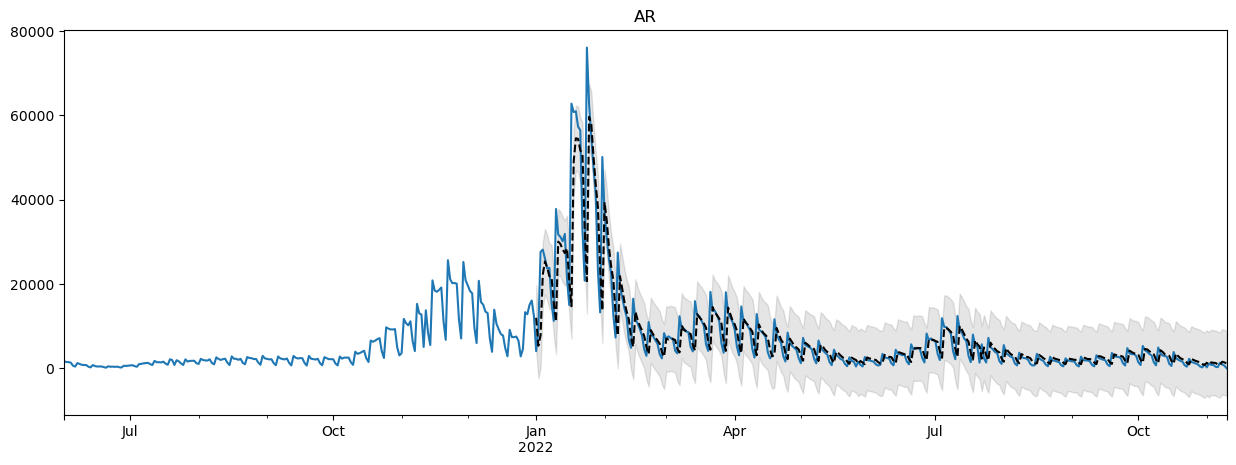

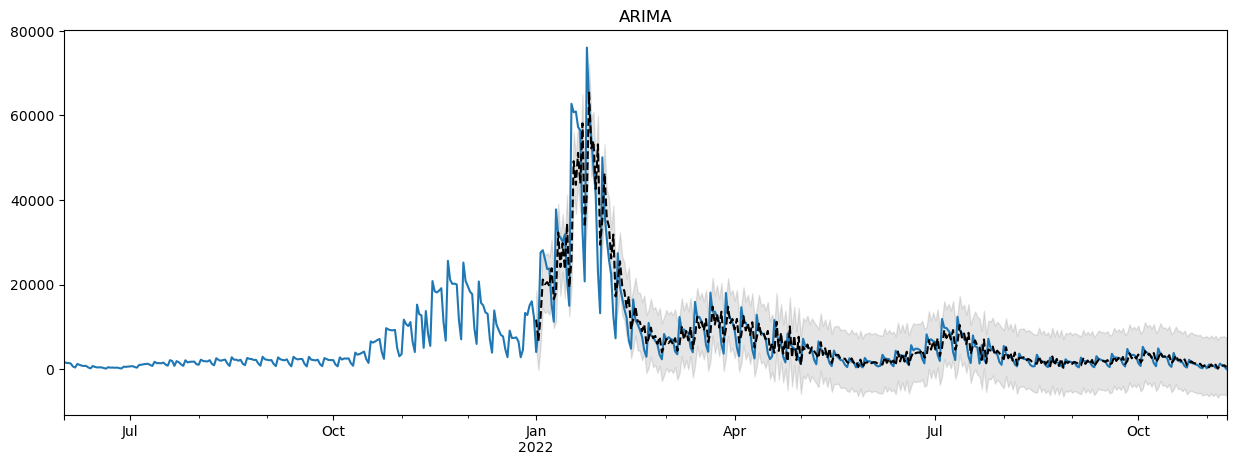

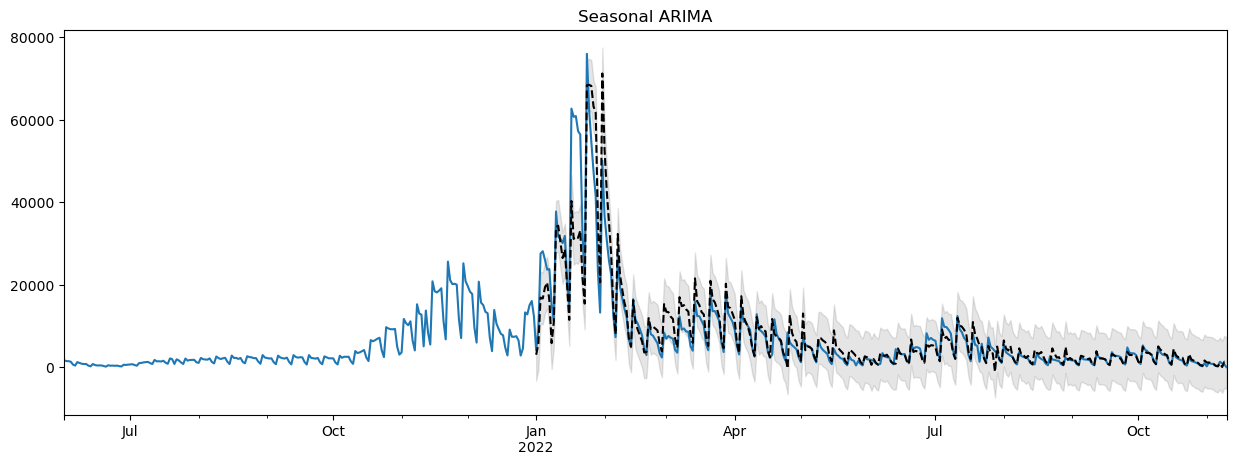

In [20]:
models = [('Simple Exponential Smoothing', SES(train)),
          ('AR', AR(train, lags=2)),
          ('ARIMA', ARIMA(train, order=(4,1,2))),
          ('Seasonal ARIMA', ARIMA(train, seasonal_order=(4,1,2,7)))]

for model_name, model in models:
  fit = model.fit()
  forecast = fit.get_prediction(start=test.index.min(), end=test.index.max()).summary_frame()

  fig, ax = plt.subplots(figsize=(15, 5))
  train.loc['2021-06':].plot(ax=ax)
  ax.set_title(model_name)

  forecast['mean'].plot(ax=ax, style='k--')
  ax.fill_between(forecast.index, forecast['mean_ci_lower'], forecast['mean_ci_upper'], color='k', alpha=0.1);

Overall, these models seem to perform relatively in line with the actual figures. We can also measure their root mean square error (RMSE) and mean absolute percentage error (MAPE) as follows:

In [21]:
for model_name, model in models:
  print('\n', model_name)
  fit = model.fit()

  # we fit the prediction starting from the lowest index in the test data
  # up to the latest index in the test data
  forecast = fit.get_prediction(start=test.index.min(), end=test.index.max()).summary_frame()

  # we take the root of the MSE
  rmse = np.sqrt(mse(test, forecast['mean']))
  mape = meanabs(test, forecast['mean'])
  print('MSE: %.3f' % rmse)
  print('MAPE: %.3f' % mape)


 Simple Exponential Smoothing
MSE: 5997.770
MAPE: 2982.675

 AR
MSE: 6110.679
MAPE: 2654.272

 ARIMA
MSE: 5384.360
MAPE: 2777.687

 Seasonal ARIMA
MSE: 4825.503
MAPE: 2301.731


It appears the seasonal ARIMA model performs best with the loweset errors for both measures. This was just by trying some random parameters. As an exercise: try some different parameters and see whether you can improve on these results.